## Import packages ###

In [1]:
##### Data Management
import os

import pandas as pd

import numpy as np

#import matplotlib.pyplot as plt

import matplotlib as mpl
import mpl_toolkits
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import plotly.graph_objects as go

import warnings
# Plotly 6 warns that Kaleido < 1.0 is deprecated; Kaleido 0.2.1 is kept because it still exports SVG/PNG without a separate Chrome installation
warnings.filterwarnings('ignore', message=r'\s*Support for Kaleido versions less than 1.0.0')

## Import own functions ###

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.general.analysis import Extract_List_Of_DataSeries_From_List_Of_Dataframes
from scientific_utils.general.analysis import Extract_List_Of_DataSeries_From_List_Of_Dataframes_And_Normalize
from scientific_utils.tof_sims.io import Read_SurfaceLab_RowBased_AreaList
from scientific_utils.tof_sims.plotting import Matplotlib_BoxPlot

## Create output folder

In [3]:
# create the output folder of it not yet exists
data_outdir = './saved_data/'
if not os.path.exists(data_outdir):
    os.mkdir(data_outdir)

In [4]:
# create the output folder of it not yet exists
images_outdir = './images/'
if not os.path.exists(images_outdir):
    os.mkdir(images_outdir)

## Read data ###

#### whole Data

In [5]:
a = path = './data/raw'
b = FilterByNameList = ['20230428_08_01_']
c = FileFormat = '.TXT'
d = StartString_of_the_wanted_Row = '\t'
e = seperation_of_the_values = '\t'
f = decimal_sign =  ','

data = Read_SurfaceLab_RowBased_AreaList(a, b, c, d, e, f)

-------------------
Following Files found in the chosen directory: %s ['20230428_07_01_washingtest.TXT', '20230428_08_01_washingtest.TXT', 'CAMDeg_washing_test_combined.TXT']
-------------------
[]
Files found: ['20230428_08_01_washingtest.TXT']
-------------------
In total 1 files are selected. 
The name of the files are: 
['20230428_08_01_washingtest.TXT']
-------------------
------------------------------------------
reading files beginning at row 2
------------------------------------------


## Dataframe with Sampledata in Columns to Dataframe with Sampledata as rows

In [6]:
data[0]

,Unnamed: 0,^2H-,Li-,LiH-,LiH_2-,B-,C-,CH-,NH-,O-,...,OF_3Al-,PO_2F_2-,AlF_4-,C_6S-,LiPO_3F-,C_8H_5O-,C_2H_4PO_4-,CH_4PNiF_2-,Ni_2O_3-,Total Counts
0,m/z,2.014700,7.0166,8.024500,9.032800,11.009700,12.0005,13.0082,15.011200,1.599520e+01,...,99.9709,1.009602e+02,102.9752,103.9717,104.9722,117.031700,122.9836,142.9441,163.854095,NaN
1,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,526.090027,16342.1300,4719.560059,4153.990234,175.020004,197564.9100,507630.1500,698.130005,1.435980e+06,...,11910.5800,2.008410e+06,248873.9500,21022.0100,199053.5300,10181.389648,118322.3000,76464.1900,11721.059570,53115131
2,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,264.040009,29033.3700,2831.120117,1463.380005,37.009998,114793.5500,264972.2200,596.099976,4.662027e+05,...,12240.8800,1.072847e+06,299149.8300,11591.6400,125205.2900,4418.279785,32565.9900,14341.1600,1932.829956,43988041
3,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,530.090027,15668.8800,4384.350098,4003.939941,87.010002,188119.7100,469536.1800,680.130005,9.946477e+05,...,22852.3500,1.788804e+06,544731.5300,38294.9000,391340.1700,13741.570312,213793.8000,61403.2900,13103.150391,76354304
4,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,205.029999,13799.1100,4061.000000,3456.459961,52.009998,128293.3500,339232.8700,462.079987,7.748146e+05,...,18265.5900,1.764296e+06,440791.3200,29886.5300,284614.1400,13525.030273,176031.9400,65877.2900,10742.839844,57850490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,367.059998,39768.1200,3958.860107,2298.739990,56.009998,155508.3800,368118.6200,631.119995,5.525798e+05,...,11231.3700,1.330434e+06,267566.1500,15111.0500,158741.1200,6393.839844,40620.5700,16184.7900,2488.199951,55618602
59,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,491.079987,13859.2000,3474.489990,2745.020020,124.019997,172859.3300,432399.8000,584.099976,1.047282e+06,...,18642.8000,1.213674e+06,447999.5000,31724.3900,328256.6000,10600.469727,174312.0700,41688.8600,10651.730469,61907715
60,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,354.049988,19630.4100,5820.709961,4792.529785,80.010002,184579.4000,497573.8500,611.109985,9.819498e+05,...,23590.5100,2.411246e+06,619409.9100,28796.9500,288018.1700,14542.139648,192243.2500,78668.8700,9897.980469,59540992
61,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,574.099976,21439.4300,6435.600098,4976.830078,123.019997,204137.3100,533805.9900,661.119995,1.203258e+06,...,19116.2500,2.555974e+06,455747.5000,30620.5400,282408.8900,13999.230469,194374.6200,87250.1600,12233.540039,66733272


In [7]:
data[0] = data[0][1:]

In [8]:
data[0]

,Unnamed: 0,^2H-,Li-,LiH-,LiH_2-,B-,C-,CH-,NH-,O-,...,OF_3Al-,PO_2F_2-,AlF_4-,C_6S-,LiPO_3F-,C_8H_5O-,C_2H_4PO_4-,CH_4PNiF_2-,Ni_2O_3-,Total Counts
1,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,526.090027,16342.13,4719.560059,4153.990234,175.020004,197564.91,507630.15,698.130005,1435980.32,...,11910.58,2008409.90,248873.95,21022.01,199053.53,10181.389648,118322.30,76464.19,11721.059570,53115131
2,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,264.040009,29033.37,2831.120117,1463.380005,37.009998,114793.55,264972.22,596.099976,466202.73,...,12240.88,1072847.09,299149.83,11591.64,125205.29,4418.279785,32565.99,14341.16,1932.829956,43988041
3,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,530.090027,15668.88,4384.350098,4003.939941,87.010002,188119.71,469536.18,680.130005,994647.71,...,22852.35,1788804.40,544731.53,38294.90,391340.17,13741.570312,213793.80,61403.29,13103.150391,76354304
4,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,205.029999,13799.11,4061.000000,3456.459961,52.009998,128293.35,339232.87,462.079987,774814.63,...,18265.59,1764295.71,440791.32,29886.53,284614.14,13525.030273,176031.94,65877.29,10742.839844,57850490
5,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,314.049988,15875.62,4623.479980,3709.659912,67.010002,146918.56,382372.56,507.089996,951803.51,...,24828.05,1852779.68,644130.60,30870.51,264569.73,12058.030273,174490.64,71425.70,10335.940430,57334040
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,367.059998,39768.12,3958.860107,2298.739990,56.009998,155508.38,368118.62,631.119995,552579.75,...,11231.37,1330434.34,267566.15,15111.05,158741.12,6393.839844,40620.57,16184.79,2488.199951,55618602
59,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,491.079987,13859.20,3474.489990,2745.020020,124.019997,172859.33,432399.80,584.099976,1047281.89,...,18642.80,1213674.46,447999.50,31724.39,328256.60,10600.469727,174312.07,41688.86,10651.730469,61907715
60,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,354.049988,19630.41,5820.709961,4792.529785,80.010002,184579.40,497573.85,611.109985,981949.78,...,23590.51,2411245.61,619409.91,28796.95,288018.17,14542.139648,192243.25,78668.87,9897.980469,59540992
61,Different_washed_Cathode_Sheets_Hold_at_4p5V (...,574.099976,21439.43,6435.600098,4976.830078,123.019997,204137.31,533805.99,661.119995,1203258.39,...,19116.25,2555973.94,455747.50,30620.54,282408.89,13999.230469,194374.62,87250.16,12233.540039,66733272


In [9]:
data[0]['Total Counts'] = pd.to_numeric(data[0]['Total Counts'], downcast="float")

C:\Users\steff\AppData\Local\Temp\ipykernel_13936\3867972478.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [10]:

list_of_substrings = ['rinsed', 'immersed', 'rinsed_immersed', 'pristine']
subdataframes = {}

for i in list_of_substrings:
    boolean = data[0]['Unnamed: 0'].str.contains(i)
    subdataframes[i] = data[0][boolean]

In [11]:
subdataframes

{'rinsed':                                            Unnamed: 0        ^2H-       Li-  \
 1   Different_washed_Cathode_Sheets_Hold_at_4p5V (...  526.090027  16342.13   
 3   Different_washed_Cathode_Sheets_Hold_at_4p5V (...  530.090027  15668.88   
 5   Different_washed_Cathode_Sheets_Hold_at_4p5V (...  314.049988  15875.62   
 7   Different_washed_Cathode_Sheets_Hold_at_4p5V (...  576.099976  17677.16   
 9   Different_washed_Cathode_Sheets_Hold_at_4p5V (...  138.020004  10150.32   
 11  Different_washed_Cathode_Sheets_Hold_at_4p5V (...  546.099976  15831.77   
 13  Different_washed_Cathode_Sheets_Hold_at_4p5V (...  121.019997   9421.05   
 15  Different_washed_Cathode_Sheets_Hold_at_4p5V (...  529.090027  14226.83   
 17  Different_washed_Cathode_Sheets_Hold_at_4p5V (...  191.029999  12984.43   
 19  Different_washed_Cathode_Sheets_Hold_at_4p5V (...  520.080017  16369.45   
 21  Different_washed_Cathode_Sheets_Hold_at_4p5V (...  268.040009  15801.27   
 23  Different_washed_Cathode_

In [12]:
# #list_of_substrings = ['_Spot\w{5}_pristine_', '_Spot\w{5}_rinsed_#', '_Spot\w{5}_immersed_#', '_Spot\w{5}_rinsed_immersed_#']
# list_of_substrings = ['Membrane 10M 25C', 'Membrane 10M 40', 'Membrane 10M 60C', 'Membrane 10M 80C']
# extracted_data = {}

# for i in subdataframes.keys():
#     dataframe = subdataframes[i]
#     for j in list_of_substrings:
#         boolean = dataframe['Unnamed: 0'].str.contains(j)
#         extracted_data[i + '_' + j] = dataframe[boolean]

In [13]:
#extracted_data.keys()

In [14]:
extracted_data = subdataframes

In [15]:
extracted_data.keys()

dict_keys(['rinsed', 'immersed', 'rinsed_immersed', 'pristine'])

In [16]:
list_of_data = []
list_of_label = []

for i in extracted_data.keys():
    dataframe = extracted_data[i]
    list_of_data.append(dataframe)
    list_of_label.append(i)

In [17]:
list_of_label

['rinsed', 'immersed', 'rinsed_immersed', 'pristine']

In [18]:
list_of_label = [list_of_label[-1]] + list_of_label[:-1]

In [19]:
list_of_label

['pristine', 'rinsed', 'immersed', 'rinsed_immersed']

In [20]:
list_of_data = [list_of_data[-1]] + list_of_data[:-1]

In [ ]:
from scientific_utils.publication_plotly import apply_style, my_color_scale, BAR_MARGIN, OVERVIEW_W_CM, OVERVIEW_H_CM, SHOW_LEGEND

# only these fragments are shown in the notebook, the box plots of all fragments are saved in ./images/
fragments_to_show = ['F-', 'LiOH-', 'CO_3-', 'LiF_2-', 'PO_2F_2-', 'NiO-']

for i in list_of_data[0].columns[1:]:
    ### Extracting Data + Normalazation
    a = list_of_data
    b = i
    c = 'Total Counts'

    #norm_data = Extract_List_of_DataSeries_From_List_Of_Dataframes_And_Normalize(a, b, c)

    norm_data = list_of_data

    ### Plot

    name = images_outdir + 'BoxPlot_' + b + 'norm_to_' + c

    a = norm_data
    b = '<sup>%s</sup>/<sub>%s</sub> <i> Fragment </i>' %(i ,c)
    c = None
    d = list_of_label
    e = name
    
    #def Plotly_DepthProfil_XPSSpectra_Plot(a, b, c, d, e, f, g, h, i, j):
    #### Define Parameters
    list_of_dataframes = list_of_data
    y_column_name = i
    list_of_curve_label  = d
    list_of_colors = e
    XAxis_Label = c
    YAxis_Label = b
    Filepath_for_saving = name

    ##### Define Figure
    # 1. Wrap the Plotly-Figure with the FigureResampler
    fig = go.Figure()
    
    for j in range(len(list_of_dataframes)):
        
        dataframe = list_of_dataframes[j]
        
        #Plotting Components
        fig.add_trace(go.Box( 
            y=dataframe[y_column_name],
            name=list_of_label[j],
            boxpoints='all', # can also be outliers, or suspectedoutliers, or False
            jitter=0.3, # add some jitter for a better separation between points
            pointpos=-1.8, # relative position of points wrt box
            boxmean=True, # True --> only shows mean line # represent mean and standard deviation
            whiskerwidth = 0.75,
            fillcolor = my_color_scale[4], # was 'royalblue'
            width = 0.25,
            opacity = 0.6,
            line = dict(
                color = 'black',
                width = 1.0),
            marker = dict(
                color = my_color_scale[4], # was 'royalblue'
                opacity = 0.6,
                size = 5,
                line = dict(
                    width = 0.75,
                    color = 'black'))
        ))
    
    ##### Change Visual Layout of the Plot: publication style (publication_plotly.apply_style), category x axis
    apply_style(fig, XAxis_Label, YAxis_Label, plot_w_cm=OVERVIEW_W_CM, plot_h_cm=OVERVIEW_H_CM, margin=BAR_MARGIN,
                x_ticks='', x_minor=False, x_tickformat=None, y_tickformat='uniform', showlegend=False,
                extra_right_px=60)   # room for the last rotated sample name   # legend would only repeat the x labels

    # Save Plot as interactive html Plot
    fig.write_html(Filepath_for_saving + ".html") # images_outdir + "Comparing_specCapacites" + ".html"

    fig.update_layout(showlegend=False)
    fig.write_image(Filepath_for_saving + ".svg")

    # fig.update_layout(showlegend=True)   # legend stays off: it only repeats the x labels (publication style)
    if i in fragments_to_show: # only the chosen fragments are shown
        fig.show()

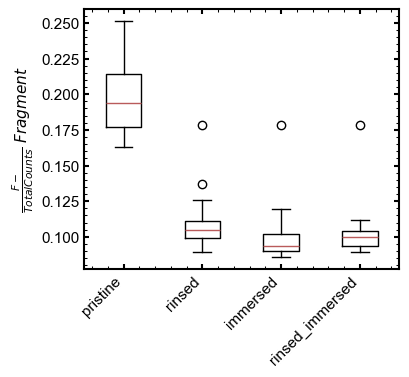

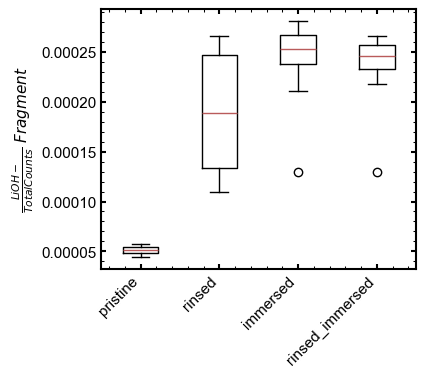

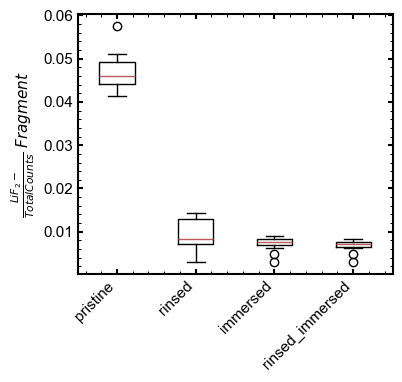

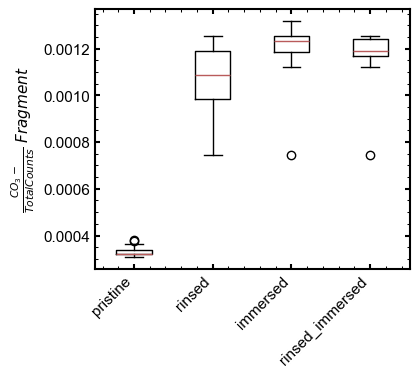

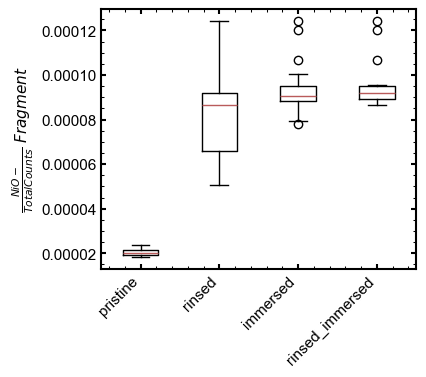

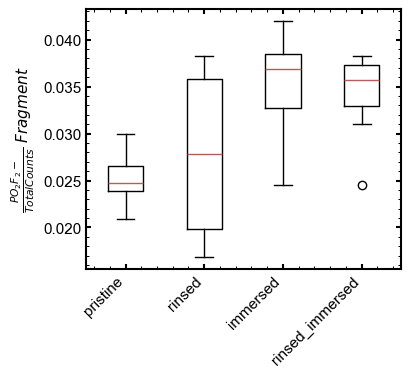

In [ ]:
for i in list_of_data[0].columns[1:]:
    ### Extracting Data + Normalazation
    a = list_of_data
    b = i
    c = 'Total Counts'

    norm_data = Extract_List_Of_DataSeries_From_List_Of_Dataframes_And_Normalize(a, b, c)

    ### Plot

    name = images_outdir + 'BoxPlot_' + b + 'norm_to_' + c +'.png'

    a = norm_data
    b = r'$\frac{%s}{%s}$ $Fragment$' %(i ,c)
    c = None
    d = list_of_label
    e = name

    Matplotlib_BoxPlot(a, b, c, d, e, show_plot=(i in fragments_to_show))

### Not Normalized

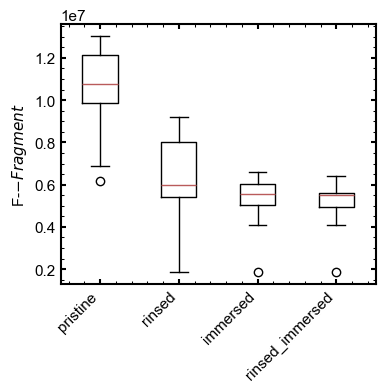

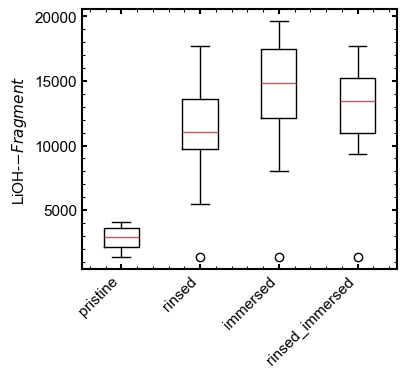

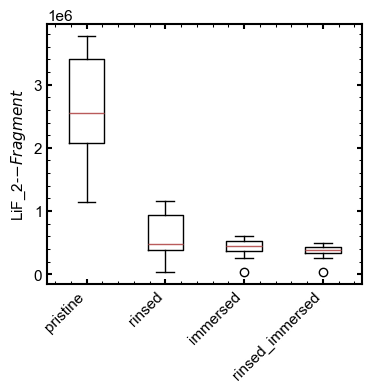

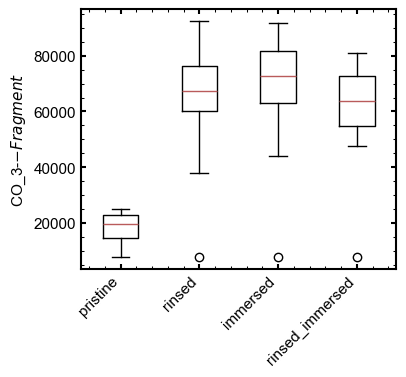

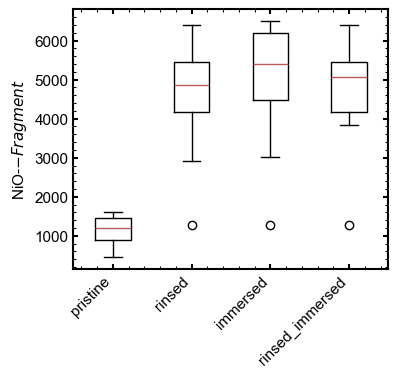

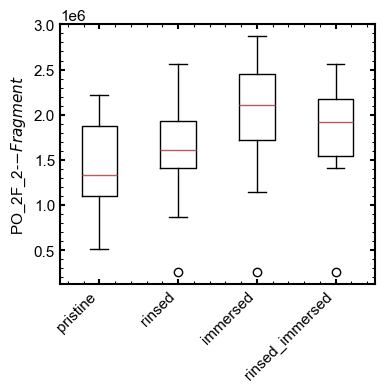

In [ ]:
for i in list_of_data[0].columns[1:]:
    ### Extracting Data + Normalazation
    a = list_of_data
    b = i

    data_extracted = Extract_List_Of_DataSeries_From_List_Of_Dataframes(a, b)

    ### Plot

    name = images_outdir + 'BoxPlot_' + b + '.png'

    a = data_extracted
    b = i + r'$-Fragment$'
    c = None
    d = list_of_label
    e = name

    Matplotlib_BoxPlot(a, b, c, d, e, show_plot=(i in fragments_to_show))